In [51]:
from plot_utils import *
from ml_util import *

import pathlib
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

Epoch 1/40 — evaluation loss: 0.9423
Epoch 2/40 — evaluation loss: 0.6426
Epoch 3/40 — evaluation loss: 0.4706
Epoch 4/40 — evaluation loss: 0.4010
Epoch 5/40 — evaluation loss: 0.3155
Epoch 6/40 — evaluation loss: 0.2749
Epoch 7/40 — evaluation loss: 0.2237
Epoch 8/40 — evaluation loss: 0.2089
Epoch 9/40 — evaluation loss: 0.1785
Epoch 10/40 — evaluation loss: 0.1565
Epoch 11/40 — evaluation loss: 0.1463
Epoch 12/40 — evaluation loss: 0.1441
Epoch 13/40 — evaluation loss: 0.1311
Epoch 14/40 — evaluation loss: 0.1217
Epoch 15/40 — evaluation loss: 0.1163
Epoch 16/40 — evaluation loss: 0.1057
Epoch 17/40 — evaluation loss: 0.0997
Epoch 18/40 — evaluation loss: 0.0970
Epoch 19/40 — evaluation loss: 0.0919
Epoch 20/40 — evaluation loss: 0.0911
Epoch 21/40 — evaluation loss: 0.0967
Epoch 22/40 — evaluation loss: 0.0875
Epoch 23/40 — evaluation loss: 0.0943
Epoch 24/40 — evaluation loss: 0.0756
Epoch 25/40 — evaluation loss: 0.0717
Epoch 26/40 — evaluation loss: 0.0723
Epoch 27/40 — evaluat

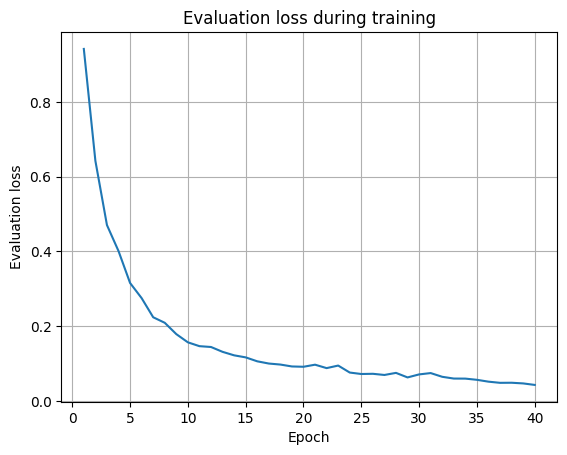

In [ ]:
training_paths = ["../dataset/real_training", "../dataset/synthetic_training"]
label_conversion = {
    "noise": 0,
    "neo": 1,
    "mini3": 2,
    "mavic4": 3
}

num_classes = 4

label_invert = {}
for k, v in label_conversion.items():
    label_invert[v] = k

def build_training_dataset(paths, algorithm, feature, size):
    data = {}
    data_size = {}

    for k in label_conversion.keys():
        data[k] = []
        data_size[k] = 0
    for path in paths:
        path_files = [p.relative_to(".") for p in pathlib.Path(path).rglob("*.npy")]
        for pf in path_files:
            label, number, algo, feat = str(pf.with_suffix("").name).split("_")
            if algo == algorithm and feat == feature:
                with open(str(pf), "rb") as fil:
                    d = np.load(fil)
                    data[label].append(d)
                    data_size[label] += d.shape[0] - FEATURE_LENGTH*2

    inputs = []
    labels = []
    for label, raw_data in data.items():
        step = data_size[label] // (size // 4)
        for d in raw_data:
            for i in range(FEATURE_LENGTH, len(d)-FEATURE_LENGTH, step):
                if feature == "mfcc":
                    inputs.append(normalize_raw_mfcc(d[i:i+FEATURE_LENGTH]))
                else:
                    inputs.append(normalize_raw_stft(d[i:i+FEATURE_LENGTH]))
                labels.append(label_conversion[label])

    return np.array(inputs), np.array(labels)

width = NMFCC
height = FEATURE_LENGTH
channels = 1
features, labels = build_training_dataset(training_paths, "nobec", "mfcc", 10000)
eval_idx = np.random.choice(len(features), 1000, replace=False)
train_idx = np.ones(len(features), dtype=np.bool)
train_idx[eval_idx] = False
train_features, train_labels = features[train_idx], labels[train_idx]
eval_features, eval_labels = features[eval_idx], labels[eval_idx]

def prepare_images(images):
    images = np.asarray(images, dtype=np.float32)

    # Reshape flattened images to PyTorch's NCHW format.
    images = images.reshape(-1, channels, height, width)

    return torch.from_numpy(images)

def prepare_labels(labels, num_classes):
    labels = np.asarray(labels)

    # Convert one-hot labels (N, Q) to class indices if needed.
    if labels.ndim == 2:
        labels = labels.argmax(axis=1)

    return torch.as_tensor(labels, dtype=torch.long)

X_train = prepare_images(train_features)
y_train = prepare_labels(train_labels, num_classes)
X_eval = prepare_images(eval_features)
y_eval = prepare_labels(eval_labels, num_classes)

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=128,
    shuffle=True,
)

class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(channels, 24, kernel_size=5, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(24, 48, kernel_size=5, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(48, 48, kernel_size=5, padding=1),
            nn.ReLU(),

            nn.Flatten(),
        )

        # Determine the flattened feature size for the configured image dimensions.
        with torch.no_grad():
            dummy = torch.zeros(1, channels, height, width)
            feature_size = self.features(dummy).shape[1]

        self.classifier = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Linear(feature_size, 16),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(16, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN(num_classes).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Evaluate the held-out data after each training epoch.
epochs = 40
eval_losses = []

for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        logits = model(X_eval.to(device))
        eval_loss = loss_fn(logits, y_eval.to(device)).item()

    eval_losses.append(eval_loss)

    print(f"Epoch {epoch + 1}/{epochs} — evaluation loss: {eval_loss:.4f}")

plt.plot(range(1, epochs + 1), eval_losses)
plt.xlabel("Epoch")
plt.ylabel("Evaluation loss")
plt.title("Evaluation loss during training")
plt.grid(True)
plt.show()

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "height": height,
        "width": width,
        "channels": channels,
        "num_classes": num_classes,
    },
    "cnn_weights.pth",
)